In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Se dispone de las tres estimaciones (optimista, más probable, pesimista; en semanas) de cada actividad. Algunas actividades tienen duración fija (las tres estimaciones coinciden).

In [3]:
pregunta_1 = "1. Calcule la duración media y la varianza de cada actividad. ¿Qué varianza tienen las actividades de duración fija?  "
pregunta_2 = "2. Determine el camino crítico y la duración media del proyecto.  "
pregunta_3 = "3. Calcule la varianza del proyecto. ¿Qué actividades contribuyen a ella? ¿Contribuye la actividad no crítica más variable? ¿Y las críticas de duración fija?  "
pregunta_4 = "4. Si pudiera reducir a cero la varianza de una sola actividad, ¿cuál elegiría para hacer el plazo más predecible? ¿Y cuál para acortarlo?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración media y la varianza de cada actividad. ¿Qué varianza tienen las actividades de duración fija?  

2. Determine el camino crítico y la duración media del proyecto.  

3. Calcule la varianza del proyecto. ¿Qué actividades contribuyen a ella? ¿Contribuye la actividad no crítica más variable? ¿Y las críticas de duración fija?  

4. Si pudiera reducir a cero la varianza de una sola actividad, ¿cuál elegiría para hacer el plazo más predecible? ¿Y cuál para acortarlo?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a, m, b 
    ('A'     , '---'      , 1, 2, 3 ),
    ('B'     , '---'      , 2, 9, 10),
    ('C'     , '---'      , 1, 3, 5 ),
    ('D'     , 'A,B,C'    , 5, 5, 5 ),
    ('E'     , 'D'        , 1, 4, 7 ),
    ('F'     , 'E'        , 5, 6, 13),
    ('G'     , 'C'        , 3, 6, 9 ),
    ('H'     , 'E,G'      , 2, 2, 2 ),
], columns=['activity', 'predecessor', 'a', 'm', 'b']).set_index('activity')
datos_enunciado

,predecessor,a,m,b
activity,,,,
A,---,1,2,3
B,---,2,9,10
C,---,1,3,5
D,"A,B,C",5,5,5
E,D,1,4,7
F,E,5,6,13
G,C,3,6,9
H,"E,G",2,2,2


# Resolución

## Apartado 1

In [5]:
display(Markdown(pregunta_1))

1. Calcule la duración media y la varianza de cada actividad. ¿Qué varianza tienen las actividades de duración fija?  

In [6]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = datos_proyecto.eval('(a + 4 * m + b) / 6').round().astype(int)
datos_proyecto['variance'] = datos_proyecto.eval('((b - a) / 6) ** 2')
datos_proyecto

,predecessor,a,m,b,duration,variance
activity,,,,,,
A,---,1,2,3,2,0.111111
B,---,2,9,10,8,1.777778
C,---,1,3,5,3,0.444444
D,"A,B,C",5,5,5,5,0.000000
E,D,1,4,7,4,1.000000
F,E,5,6,13,7,1.777778
G,C,3,6,9,6,1.000000
H,"E,G",2,2,2,2,0.000000


Cuando $a = m = b$ la varianza es $(b-a)^2/36 = 0$: la actividad no aporta incertidumbre, aunque sí aporta duración.

## Apartado 2

In [7]:
display(Markdown(pregunta_2))

2. Determine el camino crítico y la duración media del proyecto.  

In [8]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

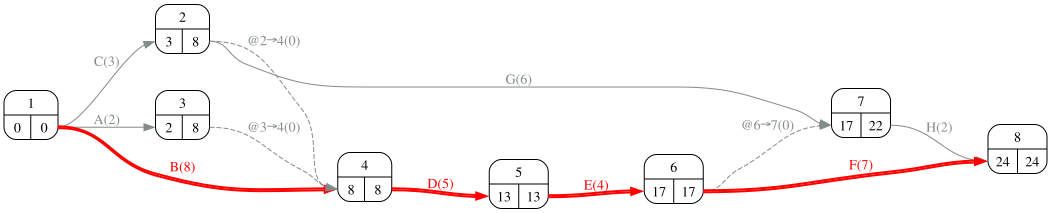

In [9]:
#| fig-cap: "Grafo PERT con duraciones medias y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
Markdown(f'La duración media del proyecto es {duracion_media} semanas.')

- Route_3 :	B, D, E, F <br> 

La duración media del proyecto es 24 semanas.

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Calcule la varianza del proyecto. ¿Qué actividades contribuyen a ella? ¿Contribuye la actividad no crítica más variable? ¿Y las críticas de duración fija?  

In [12]:
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(datos_proyecto['duration'], datos_proyecto['variance'])
display(varianza_rutas)
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
contribuyen = datos_proyecto.loc[criticas, 'variance']
mas_variable_no_critica = datos_proyecto['variance'].drop(criticas).idxmax()
pd.DataFrame({'crítica': datos_proyecto.index.isin(criticas), 'varianza': datos_proyecto['variance']}).T

,Activities,Variance
Route_3,"B, D, E, F",4.56


activity,A,B,C,D,E,F,G,H
crítica,False,True,False,True,True,True,False,False
varianza,0.111111,1.777778,0.444444,0.0,1.0,1.777778,1.0,0.0


In [13]:
Markdown(f'''La varianza del proyecto, {desviacion_proyecto**2:.3f}, es la suma de las varianzas de las actividades críticas: sólo contribuyen {", ".join(a for a in criticas if datos_proyecto.loc[a, "variance"] > 0)}. La actividad no crítica más variable, {mas_variable_no_critica} (varianza {datos_proyecto.loc[mas_variable_no_critica, "variance"]:.3f}), no cuenta en la aproximación PERT porque no está en la ruta crítica, aunque Monte Carlo mostraría que sí influye si su holgura es pequeña. Las críticas de duración fija ({", ".join(a for a in criticas if datos_proyecto.loc[a, "variance"] == 0) or "ninguna"}) aportan duración pero no varianza.''')

La varianza del proyecto, 4.556, es la suma de las varianzas de las actividades críticas: sólo contribuyen B, E, F. La actividad no crítica más variable, G (varianza 1.000), no cuenta en la aproximación PERT porque no está en la ruta crítica, aunque Monte Carlo mostraría que sí influye si su holgura es pequeña. Las críticas de duración fija (D) aportan duración pero no varianza.

## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. Si pudiera reducir a cero la varianza de una sola actividad, ¿cuál elegiría para hacer el plazo más predecible? ¿Y cuál para acortarlo?  

In [15]:
mas_variable_critica = contribuyen.idxmax()
mas_larga_critica = datos_proyecto.loc[criticas, 'duration'].idxmax()
Markdown(f'Para hacer el plazo más predecible conviene atacar la varianza de {mas_variable_critica} (la crítica de mayor varianza); '
         f'para acortarlo, la duración de alguna crítica, por ejemplo {mas_larga_critica}, la más larga. Reducir la varianza de una no crítica no cambia nada en el análisis PERT.')

Para hacer el plazo más predecible conviene atacar la varianza de B (la crítica de mayor varianza); para acortarlo, la duración de alguna crítica, por ejemplo B, la más larga. Reducir la varianza de una no crítica no cambia nada en el análisis PERT.